In [1]:
import pandas as pd
import numpy as np
import heapq
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.manifold import Isomap
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

seed=2
np.random.seed(seed)

In [2]:
df = pd.read_csv("/content/distances.csv")
display (df)

,Unnamed: 0,Ahvaz,Arak,Ardabil,Bandar Abbas,Birjand,Bojnord,Bushehr,Gorgan,Hamadan,...,Semnan,Shahr-e Kord,Shiraz,Tabriz,Tehran,Urmia,Yasuj,Yazd,Zahedan,Zanjan
0,Ahvaz,0.0,320.0,771.0,864.0,1003.0,1044.0,335.0,806.0,386.0,...,641.0,230.0,411.0,783.0,546.0,768.0,283.0,538.0,1181.0,595.0
1,Arak,320.0,0.0,479.0,991.0,893.0,784.0,585.0,526.0,133.0,...,375.0,224.0,565.0,538.0,238.0,566.0,420.0,500.0,1172.0,307.0
2,Ardabil,771.0,479.0,0.0,1436.0,1153.0,797.0,1063.0,563.0,384.0,...,541.0,698.0,1036.0,177.0,398.0,293.0,895.0,896.0,1511.0,176.0
3,Bandar Abbas,864.0,991.0,1436.0,0.0,693.0,1148.0,567.0,1085.0,1122.0,...,972.0,774.0,454.0,1527.0,1049.0,1557.0,597.0,554.0,517.0,1284.0
4,Birjand,1003.0,893.0,1153.0,693.0,0.0,539.0,912.0,619.0,1010.0,...,614.0,785.0,732.0,1304.0,780.0,1384.0,761.0,468.0,407.0,1066.0
5,Bojnord,1044.0,784.0,797.0,1148.0,539.0,0.0,1126.0,266.0,845.0,...,410.0,821.0,981.0,972.0,562.0,1080.0,922.0,676.0,945.0,789.0
6,Bushehr,335.0,585.0,1063.0,567.0,912.0,1126.0,0.0,941.0,689.0,...,778.0,378.0,181.0,1101.0,754.0,1098.0,207.0,473.0,975.0,889.0
7,Gorgan,806.0,526.0,563.0,1085.0,619.0,266.0,941.0,0.0,579.0,...,167.0,597.0,822.0,732.0,297.0,832.0,733.0,548.0,1010.0,530.0
8,Hamadan,386.0,133.0,384.0,1122.0,1010.0,845.0,689.0,579.0,0.0,...,451.0,349.0,689.0,415.0,282.0,435.0,541.0,632.0,1302.0,208.0
9,Ilam,335.0,305.0,540.0,1184.0,1191.0,1073.0,671.0,808.0,231.0,...,672.0,438.0,730.0,493.0,511.0,451.0,587.0,767.0,1441.0,385.0


In [3]:
k = 2

In [4]:
A = df.iloc[:, 1:].to_numpy()
display (A)

array([[   0.,  320.,  771.,  864., 1003., 1044.,  335.,  806.,  386.,
         335.,  317.,  541.,  805.,  366.,  242., 1145.,  562.,  421.,
         666.,  474.,  706.,  641.,  230.,  411.,  783.,  546.,  768.,
         283.,  538., 1181.,  595.],
       [ 320.,    0.,  479.,  991.,  893.,  784.,  585.,  526.,  133.,
         305.,  244.,  224.,  812.,  240.,  140.,  932.,  243.,  125.,
         354.,  283.,  411.,  375.,  224.,  565.,  538.,  238.,  566.,
         420.,  500., 1172.,  307.],
       [ 771.,  479.,    0., 1436., 1153.,  797., 1063.,  563.,  384.,
         540.,  692.,  361., 1196.,  450.,  529., 1022.,  267.,  461.,
         157.,  345.,  459.,  541.,  698., 1036.,  177.,  398.,  293.,
         895.,  896., 1511.,  176.],
       [ 864.,  991., 1436.,    0.,  693., 1148.,  567., 1085., 1122.,
        1184.,  751., 1080.,  353., 1181., 1031., 1059., 1170.,  975.,
        1284., 1263., 1085.,  972.,  774.,  454., 1527., 1049., 1557.,
         597.,  554.,  517., 1284.],


In [5]:
eps = 400

edge = [[] for _ in range(len(A))]

for i in range(len(A)):
  for j in range(len(A[i])):
    if A[i][j] <= eps and i != j:
      edge[i].append([j, A[i][j]])
print(edge)

[[[1, np.float64(320.0)], [6, np.float64(335.0)], [8, np.float64(386.0)], [9, np.float64(335.0)], [10, np.float64(317.0)], [13, np.float64(366.0)], [14, np.float64(242.0)], [22, np.float64(230.0)], [27, np.float64(283.0)]], [[0, np.float64(320.0)], [8, np.float64(133.0)], [9, np.float64(305.0)], [10, np.float64(244.0)], [11, np.float64(224.0)], [13, np.float64(240.0)], [14, np.float64(140.0)], [16, np.float64(243.0)], [17, np.float64(125.0)], [18, np.float64(354.0)], [19, np.float64(283.0)], [21, np.float64(375.0)], [22, np.float64(224.0)], [25, np.float64(238.0)], [30, np.float64(307.0)]], [[8, np.float64(384.0)], [11, np.float64(361.0)], [16, np.float64(267.0)], [18, np.float64(157.0)], [19, np.float64(345.0)], [24, np.float64(177.0)], [25, np.float64(398.0)], [26, np.float64(293.0)], [30, np.float64(176.0)]], [[12, np.float64(353.0)]], [[12, np.float64(352.0)], [15, np.float64(380.0)]], [[7, np.float64(266.0)], [15, np.float64(241.0)], [20, np.float64(392.0)]], [[0, np.float64(335.0

In [6]:
def dijkstra(adj, src):

    V = len(adj)
    pq = []
    dist = [np.inf] * V
    dist[src] = 0
    heapq.heappush(pq, (0, src))

    while pq:
        d, u = heapq.heappop(pq)

        if d > dist[u]:
            continue

        for v, w in adj[u]:
            if dist[u] + w < dist[v]:
                dist[v] = dist[u] + w
                heapq.heappush(pq, (dist[v], v))

    return dist

In [7]:
B = [[] for _ in range(len(A))]

for i in range(len(A)):
  line= dijkstra(edge, i)
  for j in line:
    B[i].append(j)

B = np.array(B, dtype=np.float64)

print(B)

[[   0.  320.  770. 1230. 1229. 1109.  335.  843.  386.  335.  317.  544.
   877.  366.  242. 1350.  563.  445.  674.  478.  733.  676.  230.  431.
   789.  558.  777.  283.  564. 1253.  594.]
 [ 320.    0.  483. 1175. 1174.  801.  602.  535.  133.  305.  244.  224.
   822.  240.  140. 1042.  243.  125.  354.  283.  413.  375.  224.  565.
   556.  238.  582.  420.  509. 1198.  307.]
 [ 770.  483.    0. 1627. 1487.  866. 1085.  600.  384.  540.  696.  361.
  1274.  457.  530. 1107.  267.  463.  157.  345.  474.  545.  707. 1045.
   177.  398.  293.  903.  961. 1650.  176.]
 [1230. 1175. 1627.    0.  705. 1326. 1156. 1457. 1308. 1433.  931. 1286.
   353. 1403. 1254. 1085. 1360. 1164. 1477. 1458. 1403. 1290. 1000.  975.
  1724. 1267. 1757.  963.  666.  729. 1475.]
 [1229. 1174. 1487.  705.    0.  621. 1155.  887. 1307. 1432.  930. 1215.
   352. 1402. 1253.  380. 1287. 1163. 1330. 1457. 1013. 1054.  999.  974.
  1634. 1184. 1730.  962.  665.  728. 1430.]
 [1109.  801.  866. 1326.  621.    

In [8]:
e = [[1] for _ in range(len(A))]
I = np.identity(len(A))
L= I - (1/len(A))*np.matmul(e,np.transpose(e))
print(L)

[[ 0.96774194 -0.03225806 -0.03225806 -0.03225806 -0.03225806 -0.03225806
  -0.03225806 -0.03225806 -0.03225806 -0.03225806 -0.03225806 -0.03225806
  -0.03225806 -0.03225806 -0.03225806 -0.03225806 -0.03225806 -0.03225806
  -0.03225806 -0.03225806 -0.03225806 -0.03225806 -0.03225806 -0.03225806
  -0.03225806 -0.03225806 -0.03225806 -0.03225806 -0.03225806 -0.03225806
  -0.03225806]
 [-0.03225806  0.96774194 -0.03225806 -0.03225806 -0.03225806 -0.03225806
  -0.03225806 -0.03225806 -0.03225806 -0.03225806 -0.03225806 -0.03225806
  -0.03225806 -0.03225806 -0.03225806 -0.03225806 -0.03225806 -0.03225806
  -0.03225806 -0.03225806 -0.03225806 -0.03225806 -0.03225806 -0.03225806
  -0.03225806 -0.03225806 -0.03225806 -0.03225806 -0.03225806 -0.03225806
  -0.03225806]
 [-0.03225806 -0.03225806  0.96774194 -0.03225806 -0.03225806 -0.03225806
  -0.03225806 -0.03225806 -0.03225806 -0.03225806 -0.03225806 -0.03225806
  -0.03225806 -0.03225806 -0.03225806 -0.03225806 -0.03225806 -0.03225806
  -0.032

In [9]:
B2_list = [[] for _ in range(len(B))]

for i in range(len(B)):
  for j in range(len(B[i])):
    B2_list[i].append(B[i][j]**2)

B2 = np.array(B2_list)
print(B2)

[[0.000000e+00 1.024000e+05 5.929000e+05 1.512900e+06 1.510441e+06
  1.229881e+06 1.122250e+05 7.106490e+05 1.489960e+05 1.122250e+05
  1.004890e+05 2.959360e+05 7.691290e+05 1.339560e+05 5.856400e+04
  1.822500e+06 3.169690e+05 1.980250e+05 4.542760e+05 2.284840e+05
  5.372890e+05 4.569760e+05 5.290000e+04 1.857610e+05 6.225210e+05
  3.113640e+05 6.037290e+05 8.008900e+04 3.180960e+05 1.570009e+06
  3.528360e+05]
 [1.024000e+05 0.000000e+00 2.332890e+05 1.380625e+06 1.378276e+06
  6.416010e+05 3.624040e+05 2.862250e+05 1.768900e+04 9.302500e+04
  5.953600e+04 5.017600e+04 6.756840e+05 5.760000e+04 1.960000e+04
  1.085764e+06 5.904900e+04 1.562500e+04 1.253160e+05 8.008900e+04
  1.705690e+05 1.406250e+05 5.017600e+04 3.192250e+05 3.091360e+05
  5.664400e+04 3.387240e+05 1.764000e+05 2.590810e+05 1.435204e+06
  9.424900e+04]
 [5.929000e+05 2.332890e+05 0.000000e+00 2.647129e+06 2.211169e+06
  7.499560e+05 1.177225e+06 3.600000e+05 1.474560e+05 2.916000e+05
  4.844160e+05 1.303210e+05 1.

In [10]:
B3= (-0.5)*np.matmul(np.matmul(L,B2),L)

print(B3)

[[ 1.92870275e+05  5.41136779e+04 -3.62875479e+04 -5.20035640e+04
  -1.67246032e+05 -2.85714467e+05  2.40008146e+05 -1.49922806e+05
   6.05527102e+04  1.56301339e+05  4.99613231e+04 -2.94016769e+04
  -3.27252092e+04  1.13959242e+05  1.09454662e+05 -4.36283258e+05
  -2.06304834e+04 -3.91123829e+01 -4.63679027e+04  7.96868876e+04
  -1.04318048e+05 -8.49100640e+04  8.76332586e+04  1.57757920e+05
   1.19419521e+04 -3.92784672e+04  5.58662263e+04  1.37905097e+05
   2.48455489e+04 -5.38175963e+04  6.08796826e+03]
 [ 5.41136779e+04  1.77570812e+04  5.59613554e+04 -7.34226608e+04
  -1.88720129e+05 -7.91310640e+04  2.73620489e+04 -2.52674027e+04
   3.86496134e+04  7.83447425e+04 -1.71187737e+04  5.92172633e+03
  -7.35593059e+04  6.45806457e+04  4.13800650e+04 -1.55471854e+05
   2.07729199e+04  3.60429084e+03  3.05555005e+04  6.63277908e+04
  -8.51464464e+03 -1.42911608e+04  1.43866181e+03  3.46932310e+03
   8.10778554e+04  5.24936004e+02  1.00812130e+05  2.19300052e+03
  -3.32035479e+04 -7.3971

In [11]:
eigenvalues, eigenvectors = np.linalg.eig(B3)
Q = eigenvectors
Q_nk = Q[:, :k]

G = np.zeros((k, k))

for i in range(k):
  if eigenvalues[i] > 0:
    G[i][i] = np.sqrt(eigenvalues[i])

print(G)

[[2509.21659308    0.        ]
 [   0.         1727.95926782]]


In [12]:
X = np.matmul(Q_nk, G)

print(X)

[[   81.24830596   413.89235562]
 [  120.0250283    107.53324196]
 [  531.11911571  -156.31445953]
 [-1013.28517408   156.9284158 ]
 [ -962.25044839  -408.68017652]
 [ -108.30316743  -694.44750129]
 [ -155.4693915    533.93618879]
 [  127.85239502  -440.54204619]
 [  251.43413576    93.74498138]
 [  343.9262794    278.36110407]
 [ -122.57564776   145.77408999]
 [  189.98982595  -106.4582516 ]
 [ -742.84342826    71.1544095 ]
 [  334.86770082   193.33603687]
 [  184.11099024   209.96527866]
 [ -420.5062461   -873.02857854]
 [  275.50153778   -99.51866914]
 [   99.16335545     9.35177415]
 [  372.21000681  -162.71460607]
 [  402.92168702   118.80599427]
 [  169.64541606  -330.16742679]
 [   85.10862085  -231.34885227]
 [  -73.89257851   220.43214155]
 [ -273.83647348   424.96841004]
 [  653.62321703   -67.99100324]
 [  159.88853677  -120.17023877]
 [  703.97004885    31.95893355]
 [ -192.65943203   339.68802304]
 [ -394.22375605   225.57452298]
 [-1034.64900696   164.10580589]
 [  407.88

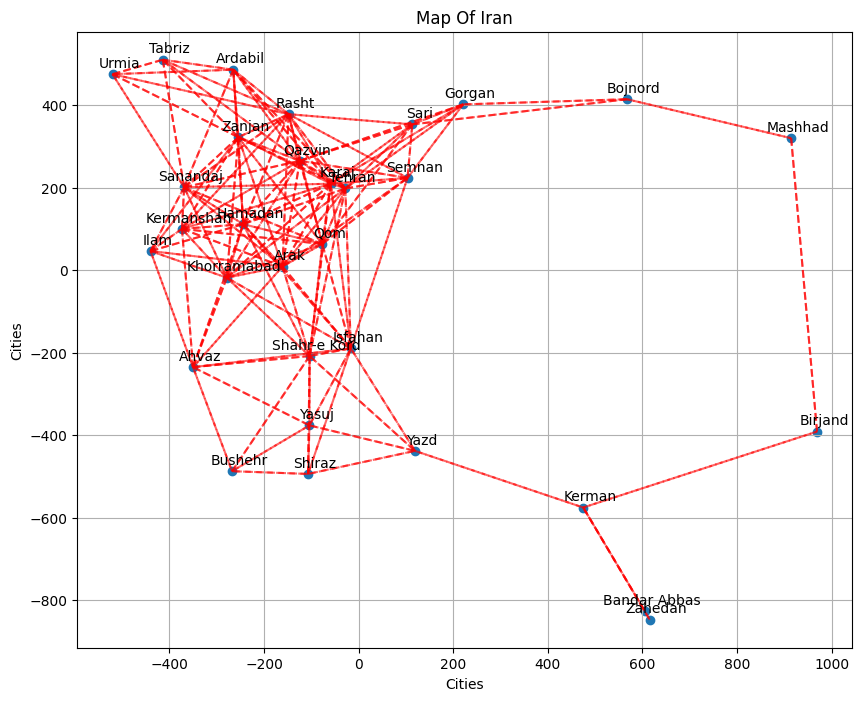

In [13]:
city_names = df['Unnamed: 0'].iloc[:len(X)].tolist()

plot_x = X[:, 1]
plot_y = X[:, 0]

plot_coords = np.vstack((plot_x, plot_y)).T

theta = np.deg2rad(45)

rotation_matrix = np.array([
    [np.cos(theta), -np.sin(theta)],
    [np.sin(theta),  np.cos(theta)]
])

plot_coords_rotated = np.dot(plot_coords, rotation_matrix)

plot_coords_rotated[:, 0] = plot_coords_rotated[:, 0] * -1

plt.figure(figsize=(10, 8))
plt.scatter(plot_coords_rotated[:, 0], plot_coords_rotated[:, 1])

for i in range(len(edge)):
    for neighbor_info in edge[i]:
        j = neighbor_info[0]
        plt.plot([plot_coords_rotated[i, 0], plot_coords_rotated[j, 0]],
                 [plot_coords_rotated[i, 1], plot_coords_rotated[j, 1]],
                 'r--', alpha=0.6)

for i, city in enumerate(city_names):
    plt.annotate(city, (plot_coords_rotated[i, 0], plot_coords_rotated[i, 1]),
                 textcoords="offset points", xytext=(5,5), ha='center')

plt.xlabel('Cities')
plt.ylabel('Cities')
plt.title('Map Of Iran')
plt.grid(True)
plt.show()

Using Isomap function from scikit library:

In [14]:
X_input = A

isomap = Isomap(n_neighbors=None, radius=eps, metric='precomputed')
X_transformed = isomap.fit_transform(X_input)

/tmp/ipython-input-3828495700.py:19: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  scatter = plt.scatter(plot_coords_rotated_isomap[:, 0], plot_coords_rotated_isomap[:, 1], cmap='viridis', edgecolors='k', s=20)


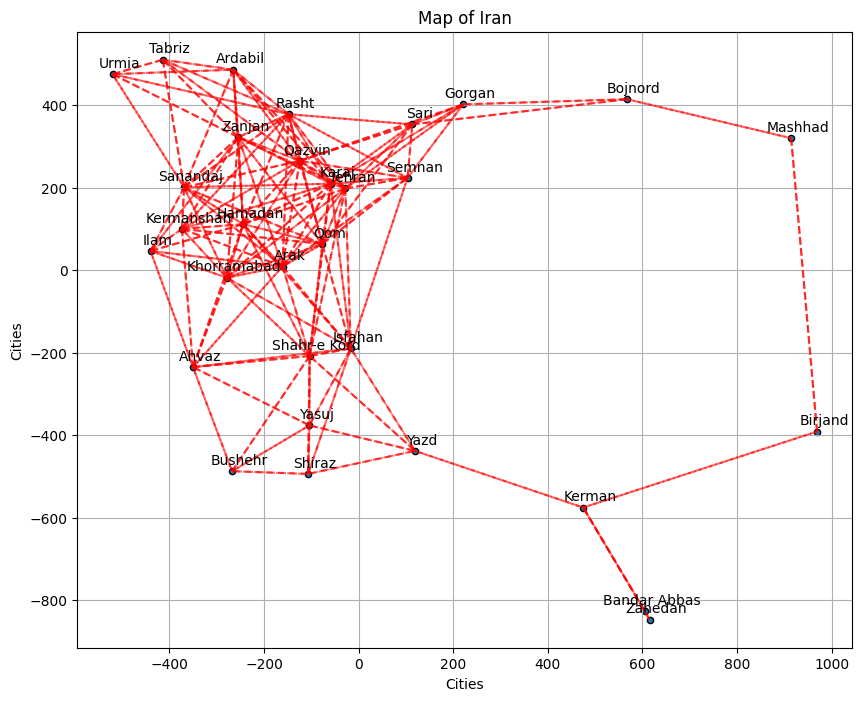

In [15]:
city_names = df['Unnamed: 0'].iloc[:len(X_transformed)].tolist()

plot_x_isomap = X_transformed[:, 1]
plot_y_isomap = X_transformed[:, 0]

plot_coords_isomap = np.vstack((plot_x_isomap, plot_y_isomap)).T
theta = np.deg2rad(45)

rotation_matrix = np.array([
    [np.cos(theta), -np.sin(theta)],
    [np.sin(theta),  np.cos(theta)]
])

plot_coords_rotated_isomap = np.dot(plot_coords_isomap, rotation_matrix)

plot_coords_rotated_isomap[:, 1] = plot_coords_rotated_isomap[:, 1] * -1

plt.figure(figsize=(10, 8))
scatter = plt.scatter(plot_coords_rotated_isomap[:, 0], plot_coords_rotated_isomap[:, 1], cmap='viridis', edgecolors='k', s=20)

for i in range(len(edge)):
    for neighbor_info in edge[i]:
        j = neighbor_info[0]
        plt.plot([plot_coords_rotated_isomap[i, 0], plot_coords_rotated_isomap[j, 0]],
                 [plot_coords_rotated_isomap[i, 1], plot_coords_rotated_isomap[j, 1]],
                 'r--', alpha=0.6)

for i, city in enumerate(city_names):
    plt.annotate(city, (plot_coords_rotated_isomap[i, 0], plot_coords_rotated_isomap[i, 1]),
                 textcoords="offset points", xytext=(5,5), ha='center')

plt.title('Map of Iran')
plt.xlabel('Cities')
plt.ylabel('Cities')

plt.grid(True)
plt.show()